# 03 — EDA: US transfer-test sites (NREL PVDAQ)
**Purpose:** decide whether Henderson NV (1423) and Golden CO (50) can serve as unseen test sites for the DKASC-trained system, *before* any cleaning.
Questions: (1) coverage, (2) timestamps / time zone, (3) units + capacity, (4) sensor health, (5) which 12-month test window.
Input: `data/interim/pvdaq_<id>_hourly.csv`, `_daily.csv` from `python -m src.data.pvdaq` (raw values, no cleaning).

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")  # imports and paths are relative to the project root
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pvlib
from pathlib import Path
from src.data.pvdaq import SITES
FIG = Path('results/pvdaq_eda'); FIG.mkdir(parents=True, exist_ok=True)
H = {s: pd.read_csv(f'data/interim/pvdaq_{s}_hourly.csv', index_col=0, parse_dates=True) for s in SITES}
D = {s: pd.read_csv(f'data/interim/pvdaq_{s}_daily.csv', index_col=0, parse_dates=True) for s in SITES}
INK, MUTED, S1, S2 = '#1B2A3A', '#6B7280', '#2A78D6', '#EB6834'
def style(ax):
    ax.spines[['top','right']].set_visible(False); ax.tick_params(labelsize=8, colors=MUTED); ax.grid(color='#E6E6E3', lw=0.6); ax.set_axisbelow(True)

## 1. Coverage — share of minutes recorded per day

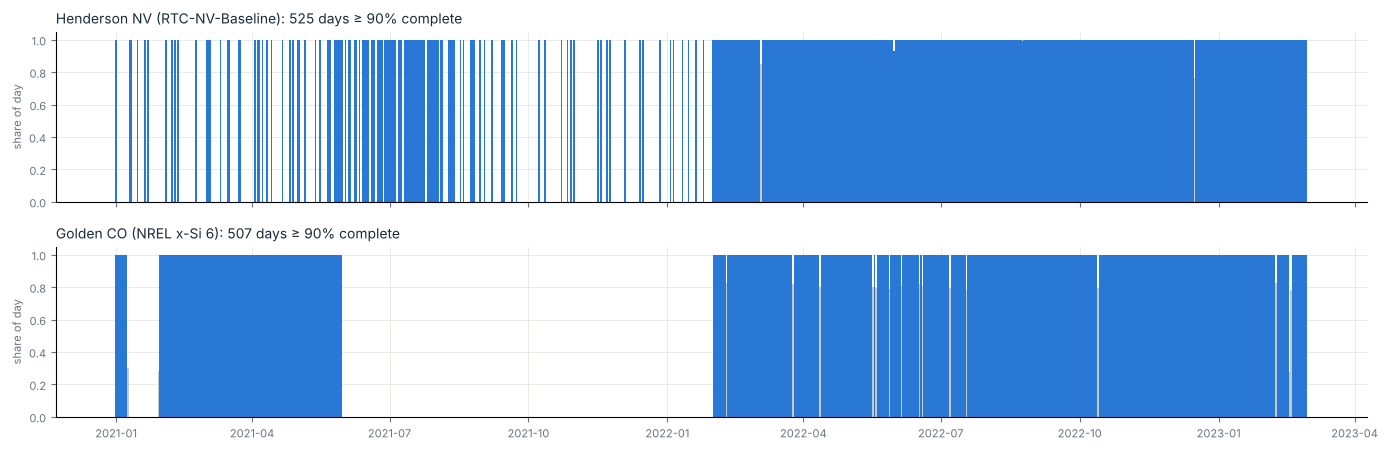

Henderson NV (RTC-NV-Baseline)
measured_on    2021-01  2021-02  2021-03  2021-04  2021-05  2021-06  2021-07  2021-08  2021-09  2021-10  2021-11  2021-12  2022-01  2022-02  2022-03  2022-04  2022-05  2022-06  2022-07  2022-08  2022-09  2022-10  2022-11  2022-12  2023-01  2023-02
complete days        6        5        8        9       14       21       28       15        7        6        4        4        7       28       30       30       31       30       31       31       30       31       30       30       31       28
Golden CO (NREL x-Si 6)
measured_on    2021-01  2021-02  2021-03  2021-04  2021-05  2021-06  2021-07  2021-08  2021-09  2021-10  2021-11  2021-12  2022-01  2022-02  2022-03  2022-04  2022-05  2022-06  2022-07  2022-08  2022-09  2022-10  2022-11  2022-12  2023-01  2023-02
complete days       10       28       31       30       30        0        0        0        0        0        0        0        0       27       30       29       28       27       29       31       3

In [2]:
fig, axs = plt.subplots(2, 1, figsize=(14, 4.6), sharex=True)
for ax, s in zip(axs, SITES):
    cov = D[s].n_min / 1440
    ax.bar(cov.index, cov, width=1, color=np.where(cov >= 0.9, S1, '#C8C8C4'))
    ax.set_ylabel('share of day', fontsize=8, color=MUTED); style(ax)
    ax.set_title(f"{SITES[s]['name']}: {int((cov>=0.9).sum())} days ≥ 90% complete", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'01_coverage.png', dpi=150); plt.show()
for s in SITES:
    m = (D[s].n_min >= 0.9*1440).groupby(D[s].index.to_period('M')).sum()
    print(SITES[s]['name']); print(m.to_frame('complete days').T.to_string())

## 2. Timestamps — local standard time or daylight saving?
Compare each day's power-weighted centre time with the centre of *modelled* clear-sky plane-of-array irradiance
for the array's tilt/azimuth in local **standard** time (Henderson UTC−8, Golden UTC−7). Daylight-saving timestamps would show a
+60 min step from March to November.

Henderson NV (RTC-NV-Baseline): median offset summer +3.5 min, winter +3.9 min


Golden CO (NREL x-Si 6): median offset summer -1.5 min, winter +6.5 min


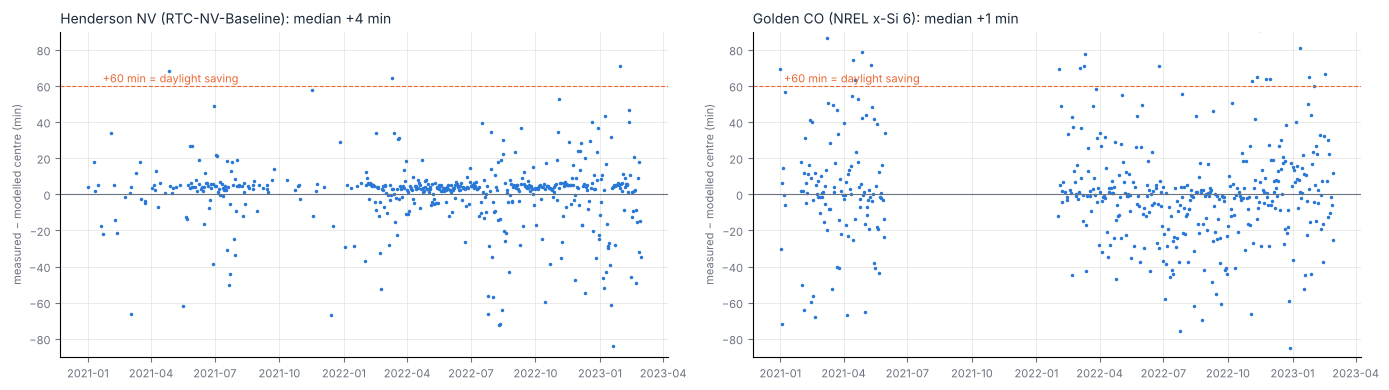

In [3]:
TZ = {1423: 'Etc/GMT+8', 50: 'Etc/GMT+7'}  # fixed offsets = standard time all year
def modelled_centroid(s, days):
    p = SITES[s]; loc = pvlib.location.Location(p['lat'], p['lon'], TZ[s], p['alt'])
    out = {}
    for d in days:
        t = pd.date_range(d, periods=144, freq='10min', tz=TZ[s]) + pd.Timedelta(minutes=5)
        cs = loc.get_clearsky(t); sp = loc.get_solarposition(t)
        poa = pvlib.irradiance.get_total_irradiance(p['tilt'], p['az'], sp.apparent_zenith, sp.azimuth, cs.dni, cs.ghi, cs.dhi).poa_global
        mins = t.hour*60 + t.minute
        out[d] = float((poa*mins).sum()/poa.sum())
    return pd.Series(out)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, s in zip(axs, SITES):
    d = D[s][D[s].n_min >= 0.9*1440]
    mod = modelled_centroid(s, d.index)
    diff = d.centroid_min - mod
    ax.plot(d.index, diff, '.', ms=3, color=S1)
    ax.axhline(0, color=MUTED, lw=0.8); ax.axhline(60, color=S2, lw=0.8, ls='--')
    ax.text(d.index[5], 62, '+60 min = daylight saving', fontsize=8, color=S2)
    ax.set_ylim(-90, 90); ax.set_ylabel('measured − modelled centre (min)', fontsize=8, color=MUTED); style(ax)
    ax.set_title(f"{SITES[s]['name']}: median {diff.median():+.0f} min", fontsize=10, color=INK, loc='left')
    summer = diff[(d.index.month >= 4) & (d.index.month <= 10)].median(); winter = diff[(d.index.month <= 2) | (d.index.month == 12)].median()
    print(f"{SITES[s]['name']}: median offset summer {summer:+.1f} min, winter {winter:+.1f} min")
fig.tight_layout(); fig.savefig(FIG/'02_timestamps.png', dpi=150); plt.show()

## 3. Units and capacity — AC power vs plane-of-array irradiance (hourly)

Henderson NV (RTC-NV-Baseline): median AC/POA above 600 W/m² = 5.02 kW per kW/m² → implied size at PR 0.8 ≈ 6.27 kWp; max hourly AC 6.13 kW; night (POA<1) mean AC -2.9 W
Golden CO (NREL x-Si 6): median AC/POA above 600 W/m² = -0.00 kW per kW/m² → implied size at PR 0.8 ≈ -0.00 kWp; max hourly AC 5.17 kW; night (POA<1) mean AC 3.1 W


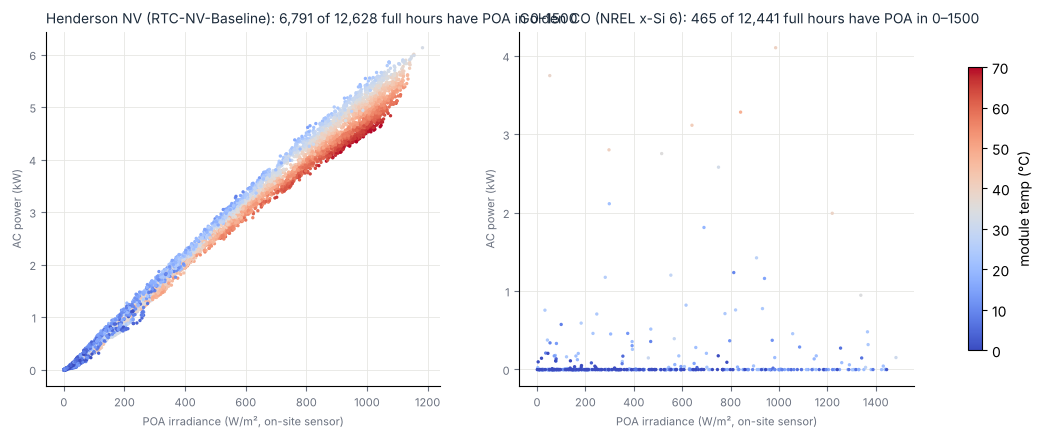

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, s in zip(axs, SITES):
    h = H[s][(H[s].n_min == 60)]
    ok = h.poa.between(0, 1500)
    sc = ax.scatter(h.poa[ok], h.p_w[ok]/1000, c=h.t_mod[ok], s=2, cmap='coolwarm', vmin=0, vmax=70)
    ax.set_xlabel('POA irradiance (W/m², on-site sensor)', fontsize=8, color=MUTED); ax.set_ylabel('AC power (kW)', fontsize=8, color=MUTED)
    style(ax); ax.set_title(f"{SITES[s]['name']}: {ok.sum():,} of {len(h):,} full hours have POA in 0–1500", fontsize=10, color=INK, loc='left')
    q = (h.p_w[ok & (h.poa > 600)] / h.poa[ok & (h.poa > 600)]).median()  # W per W/m2
    print(f"{SITES[s]['name']}: median AC/POA above 600 W/m² = {q:.2f} kW per kW/m² → implied size at PR 0.8 ≈ {q/0.8:.2f} kWp; "
          f"max hourly AC {h.p_w.max()/1000:.2f} kW; night (POA<1) mean AC {h.p_w[h.poa.between(-50,1)].mean():.1f} W")
fig.colorbar(sc, ax=axs, label='module temp (°C)', shrink=0.8); fig.savefig(FIG/'03_power_vs_poa.png', dpi=150); plt.show()

## 4. Sensor health — POA irradiance distribution and timeline

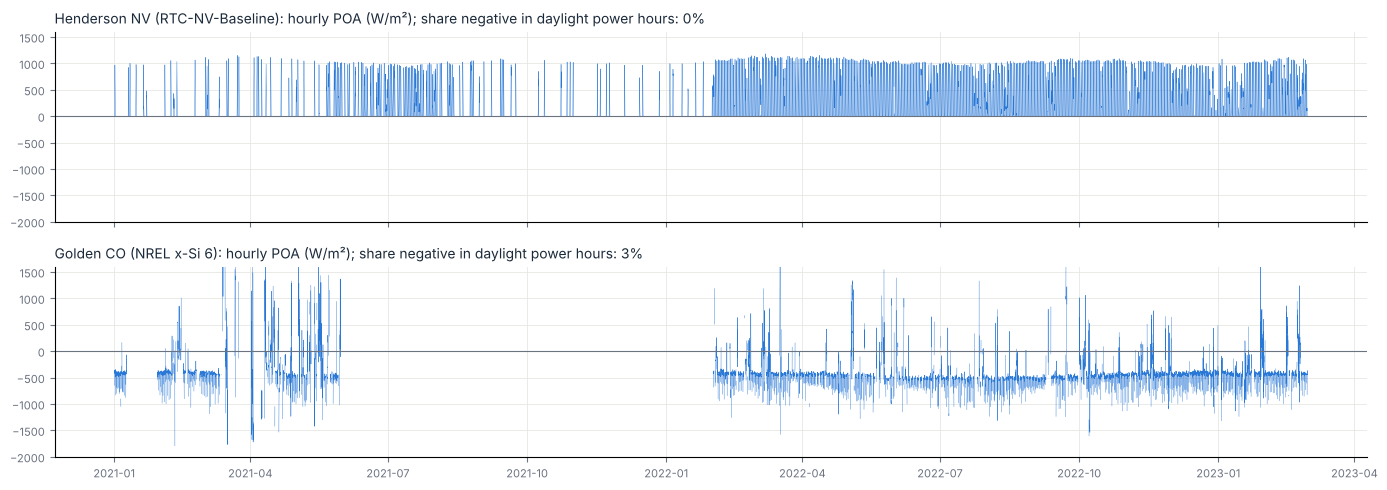

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for ax, s in zip(axs, SITES):
    h = H[s]
    ax.plot(h.index, h.poa, lw=0.3, color=S1)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylim(-2000, 1600); style(ax)
    ax.set_title(f"{SITES[s]['name']}: hourly POA (W/m²); share negative in daylight power hours: "
                 f"{((h.poa < -20) & (h.p_w > 500)).sum() / max(1,(h.p_w > 500).sum()):.0%}", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'04_poa_health.png', dpi=150); plt.show()

## 5. Daily energy vs clear-sky potential — gaps, outages, degradation

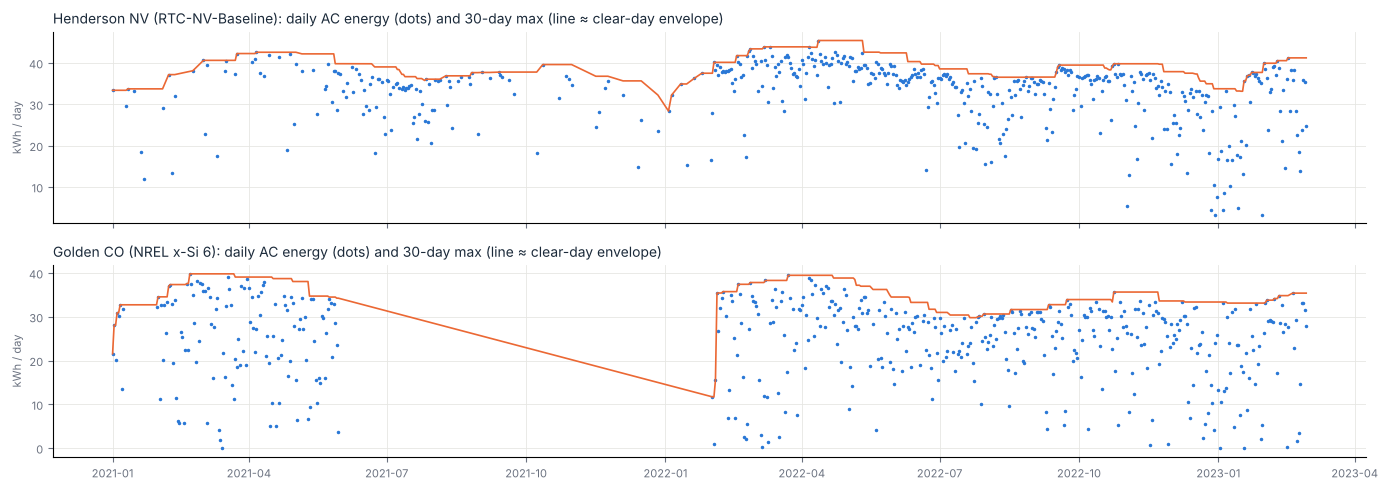

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for ax, s in zip(axs, SITES):
    d = D[s][D[s].n_min >= 0.9*1440]
    ax.plot(d.index, d.kwh, '.', ms=3, color=S1)
    top = d.kwh.rolling('30D').max()
    ax.plot(top.index, top, color=S2, lw=1.2)
    ax.set_ylabel('kWh / day', fontsize=8, color=MUTED); style(ax)
    ax.set_title(f"{SITES[s]['name']}: daily AC energy (dots) and 30-day max (line ≈ clear-day envelope)", fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(FIG/'05_daily_energy.png', dpi=150); plt.show()

## 6. Candidate 12-month test windows (days ≥ 90% complete per window)

In [7]:
for s in SITES:
    ok = (D[s].n_min >= 0.9*1440)
    starts = pd.date_range('2021-01-01', '2022-03-01', freq='MS')
    w = {f"{a:%Y-%m}..{a + pd.DateOffset(months=12) - pd.Timedelta(days=1):%Y-%m}": int(ok[a:a + pd.DateOffset(months=12) - pd.Timedelta(days=1)].sum()) for a in starts}
    best = max(w, key=w.get)
    print(f"{SITES[s]['name']}: best window {best} with {w[best]} complete days; " + ", ".join(f"{k}:{v}" for k, v in list(w.items())[-4:]))

Henderson NV (RTC-NV-Baseline): best window 2022-02..2023-01 with 363 complete days; 2021-12..2022-11:313, 2022-01..2022-12:339, 2022-02..2023-01:363, 2022-03..2023-02:363
Golden CO (NREL x-Si 6): best window 2022-02..2023-01 with 353 complete days; 2021-12..2022-11:291, 2022-01..2022-12:322, 2022-02..2023-01:353, 2022-03..2023-02:351
